In [1]:
!pip install umap-learn

In [2]:
!pip install yellowbrick

## **K-means Distortion / Elbow**

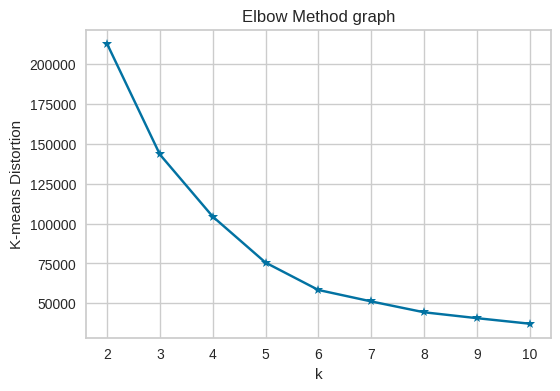

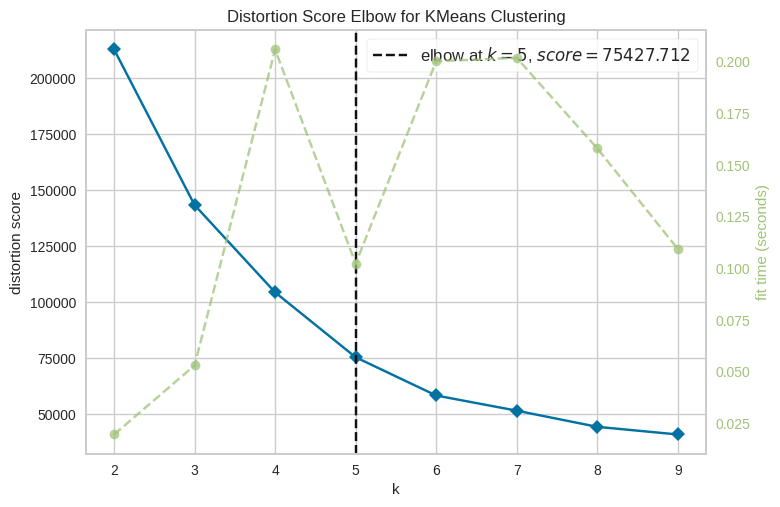

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [3]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.metrics import pairwise_distances
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from yellowbrick.cluster import KElbowVisualizer

df = pd.read_csv('/content/drive/MyDrive/customers_dataset.csv')

# encode categorical 'Gender'
df['Gender'] = LabelEncoder().fit_transform(df['Gender'])

inertia = []
K = range(2,11)
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10)
    kmeanModel.fit(df[['Gender', 'Age', 'Income', 'Score']])
    inertia.append(kmeanModel.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K, inertia, 'b*-')
plt.xlabel('k')
plt.ylabel('K-means Distortion')
plt.title('Elbow Method graph')
plt.show()

# ======================================

km = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(km, k=(2,10))

visualizer.fit(df[['Gender', 'Age', 'Income', 'Score']])
visualizer.show()

## **Silhouette Score**

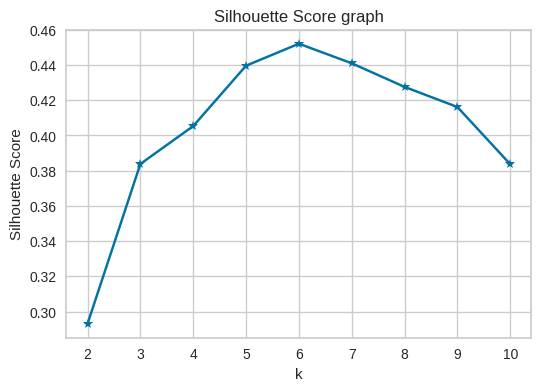

In [4]:
silh_scores = []
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10)
    kmeanModel.fit(df[['Gender', 'Age', 'Income', 'Score']])
    silh_scores.append(silhouette_score(df[['Gender', 'Age', 'Income', 'Score']], kmeanModel.labels_))

plt.figure(figsize=(6,4))
plt.plot(K, silh_scores, 'b*-')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score graph')
plt.show()

## **Davies-Bouldin Index**

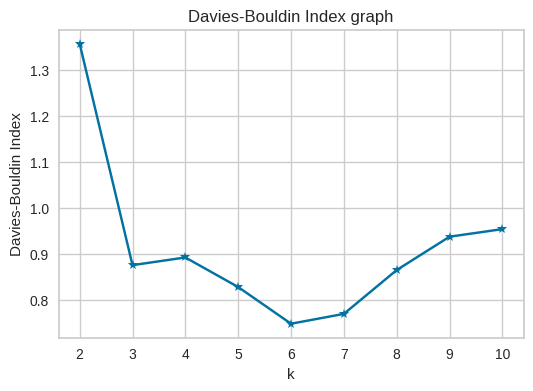

In [5]:
db_scores = []
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10)
    kmeanModel.fit(df[['Gender', 'Age', 'Income', 'Score']])
    db_scores.append(davies_bouldin_score(df[['Gender', 'Age', 'Income', 'Score']], kmeanModel.labels_))

plt.figure(figsize=(6,4))
plt.plot(K, db_scores, 'b*-')
plt.xlabel('k')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin Index graph')
plt.show()

## **Calinski-Harabasz Index**

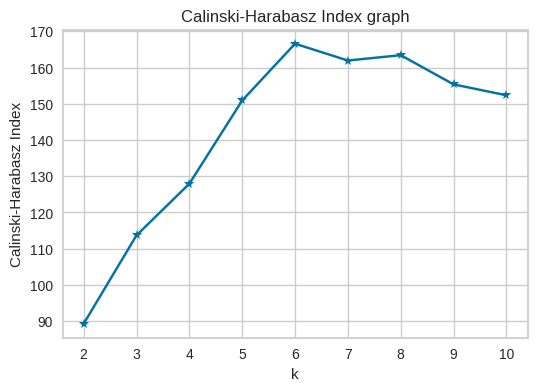

In [6]:
ch_scores = []
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10)
    kmeanModel.fit(df[['Gender', 'Age', 'Income', 'Score']])
    ch_scores.append(calinski_harabasz_score(df[['Gender', 'Age', 'Income', 'Score']], kmeanModel.labels_))

plt.figure(figsize=(6,4))
plt.plot(K, ch_scores, 'b*-')
plt.xlabel('k')
plt.ylabel('Calinski-Harabasz Index')
plt.title('Calinski-Harabasz Index graph')
plt.show()

## **Dunn Index**

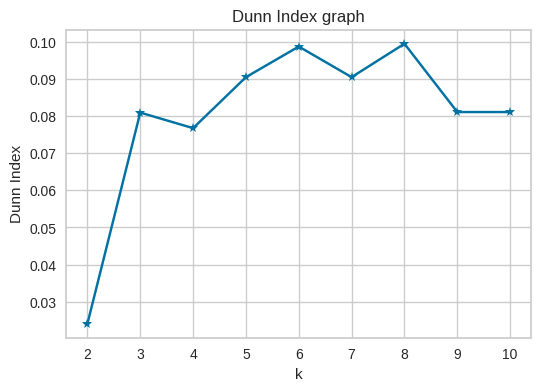

In [7]:
def dunn_index(X, labels):
    unique_cluster_labels = np.unique(labels)
    num_clusters = len(unique_cluster_labels)

    # intra-cluster distances
    intra_dists = []
    for label in unique_cluster_labels:
        cluster_points = X[labels == label]
        if len(cluster_points) > 1:
            intra_dists.append(np.max(pairwise_distances(cluster_points)))

    # inter-cluster distances
    inter_dists = []
    for i in range(num_clusters):
        for j in range(i + 1, num_clusters):
            cluster_i_points = X[labels == unique_cluster_labels[i]]
            cluster_j_points = X[labels == unique_cluster_labels[j]]
            inter_dists.append(np.min(pairwise_distances(cluster_i_points, cluster_j_points)))
    return np.min(inter_dists) / np.max(intra_dists)

dunn_indices = []
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10, random_state=64)
    labels = kmeanModel.fit_predict(df[['Gender', 'Age', 'Income', 'Score']])
    dunn_indices.append(dunn_index(df[['Gender', 'Age', 'Income', 'Score']].values, labels))

plt.figure(figsize=(6,4))
plt.plot(K, dunn_indices, 'b*-')
plt.xlabel('k')
plt.ylabel('Dunn Index')
plt.title('Dunn Index graph')
plt.show()

## **Plotting All**

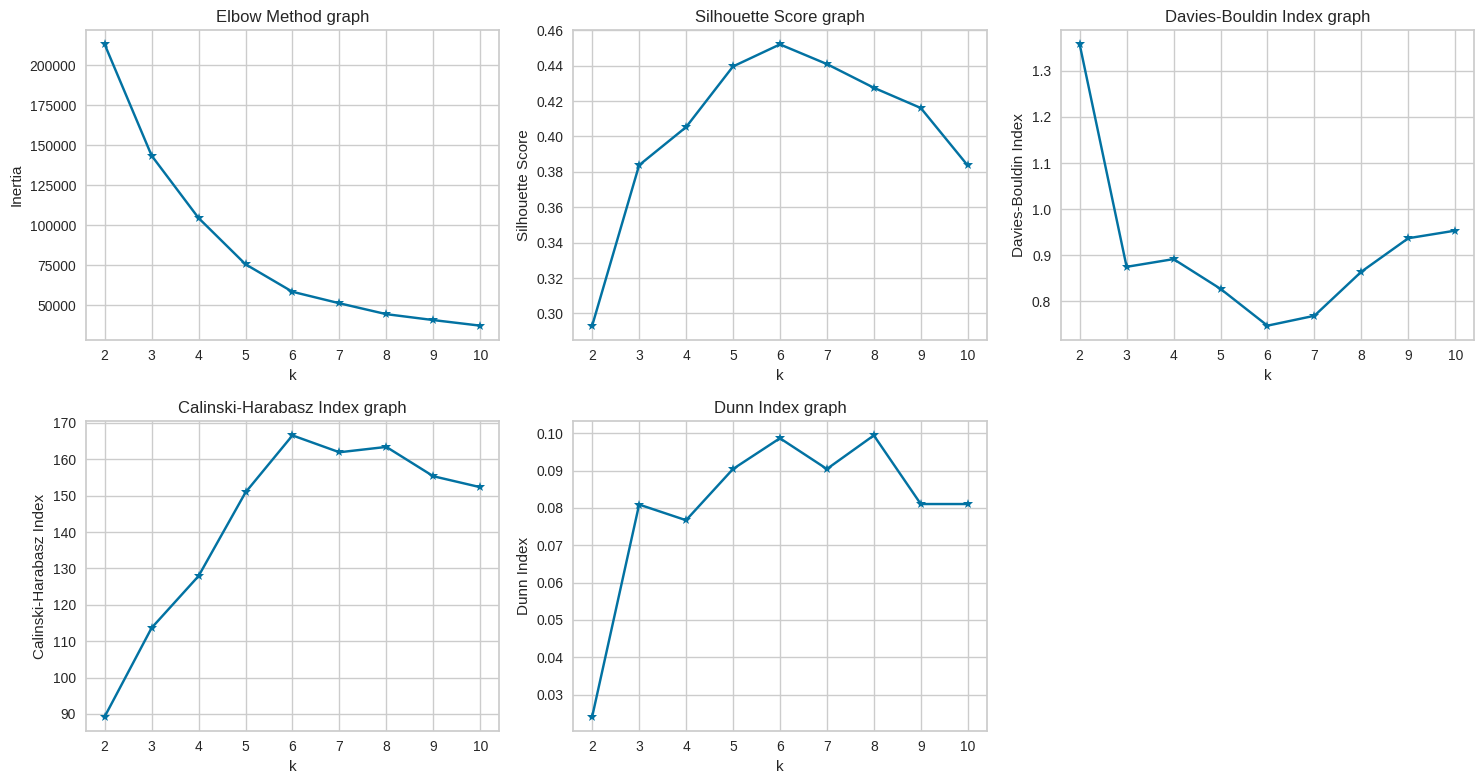

In [8]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.plot(K, inertia, 'b*-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method graph')

plt.subplot(2, 3, 2)
plt.plot(K, silh_scores, 'b*-')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score graph')

plt.subplot(2, 3, 3)
plt.plot(K, db_scores, 'b*-')
plt.xlabel('k')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin Index graph')

plt.subplot(2, 3, 4)
plt.plot(K, ch_scores, 'b*-')
plt.xlabel('k')
plt.ylabel('Calinski-Harabasz Index')
plt.title('Calinski-Harabasz Index graph')

plt.subplot(2, 3, 5)
plt.plot(K, dunn_indices, 'b*-')
plt.xlabel('k')
plt.ylabel('Dunn Index')
plt.title('Dunn Index graph')

plt.tight_layout()
plt.show()

## **1- PCA**

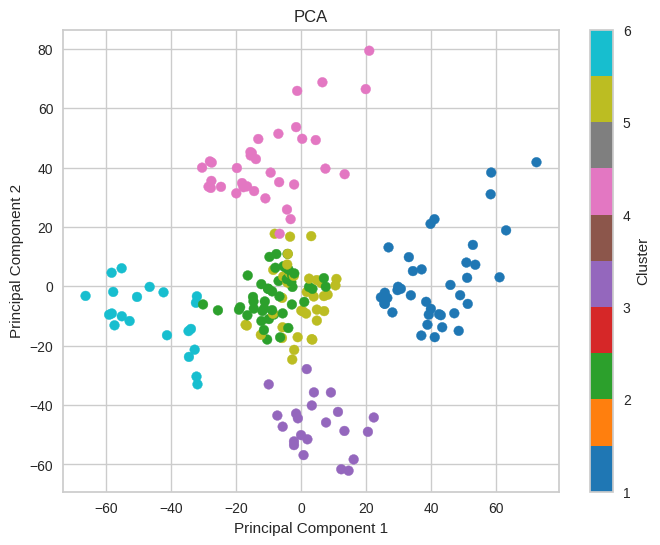

In [9]:
optimal_k = 6

# K-means
kmeanModel = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
df['Cluster'] = kmeanModel.fit_predict(df[['Gender', 'Age', 'Income', 'Score']])

# PCA
pca = PCA(n_components=2, random_state=42)
principal_components = pca.fit_transform(df[['Gender', 'Age', 'Income', 'Score']], df['Cluster'])
df['PCA 1'] = principal_components[:,0]
df['PCA 2'] = principal_components[:,1]

plt.figure(figsize=(8, 6))
plt.scatter(df['PCA 1'], df['PCA 2'], c=kmeanModel.labels_ + 1, cmap='tab10')
plt.title('PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.show()

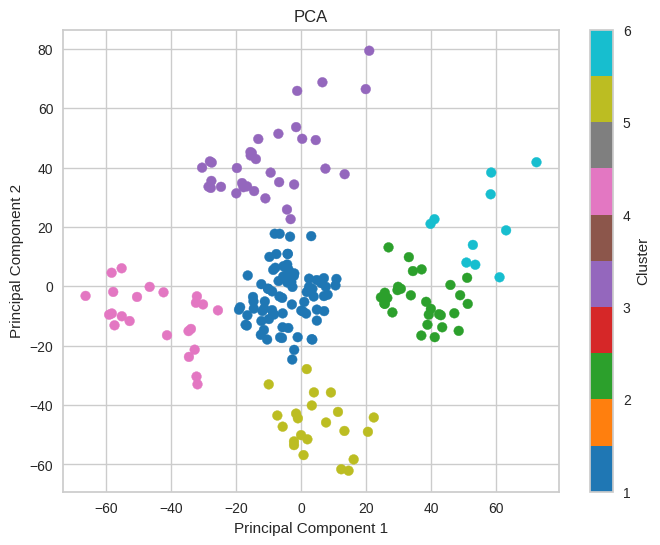

In [24]:
# optimal_k = 6

# # PCA and transform data
# pca = PCA(n_components=2)
# principal_components = pca.fit_transform(df[['Gender', 'Age', 'Income', 'Score']])

# # KMeans clustering
# kmeans = KMeans(n_clusters=optimal_k, n_init=10)
# kmeans.fit(principal_components)

# plt.figure(figsize=(8, 6))
# plt.scatter(principal_components[:, 0], principal_components[:, 1], c=kmeans.labels_ + 1, cmap='tab10')
# plt.title('PCA')
# plt.xlabel('Principal Component 1')
# plt.ylabel('Principal Component 2')
# plt.colorbar(label='Cluster')
# plt.show()

            PCA1      PCA2
Gender -0.000333  0.001579
Age    -0.188977  0.130961
Income  0.588623  0.808388
Score   0.786009 -0.573895


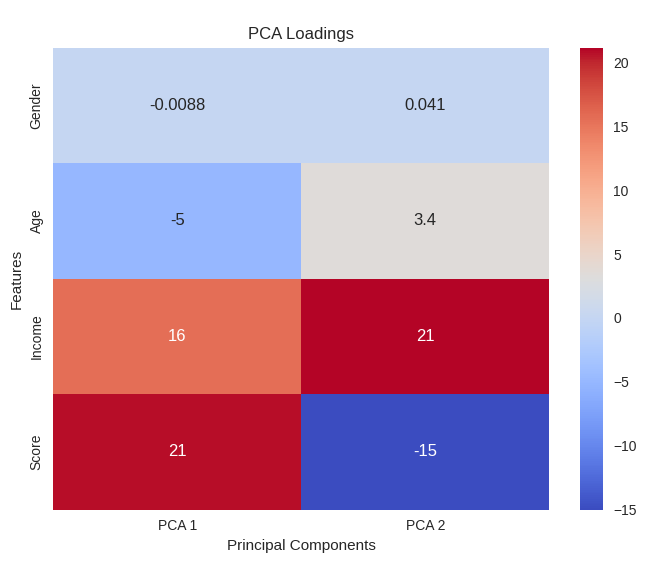

In [11]:
# feature importance
loadings = pd.DataFrame(pca.components_.T, columns=['PCA1', 'PCA2'], index=['Gender', 'Age', 'Income', 'Score'])
print(loadings)

# PCA loadings
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings, columns=['PCA 1', 'PCA 2'], index=['Gender', 'Age', 'Income', 'Score'])

# loadings
plt.figure(figsize=(8, 6))
sns.heatmap(loadings_df, annot=True, cmap='coolwarm')
plt.title('\nPCA Loadings')
plt.xlabel('Principal Components')
plt.ylabel('Features')
plt.show()

Correlation absolute between features and cluster labels (PCA):
PCA 1     0.697336
Score     0.648021
Income    0.370784
Age       0.163756
PCA 2     0.054722
Gender    0.050626
Name: Cluster, dtype: float64


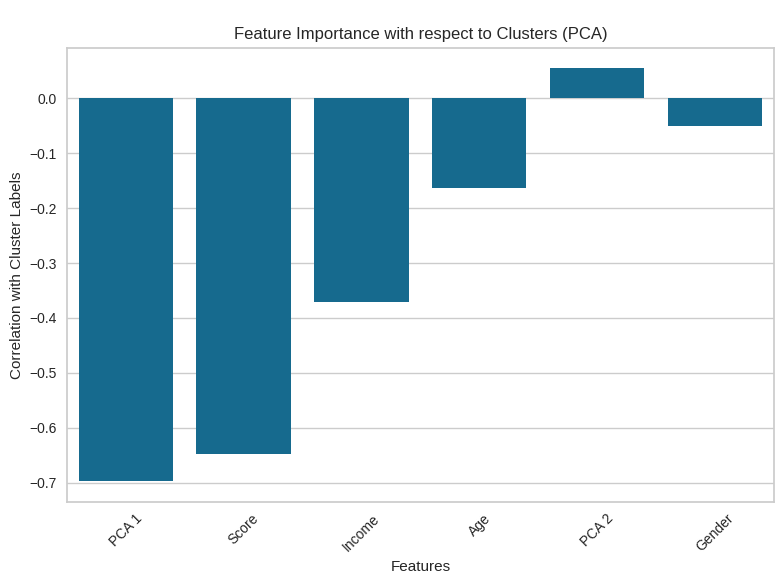

In [12]:
# correlation between features and cluster labels (PCA)
correlation_matrix = df[['Gender', 'Age', 'Income', 'Score', 'PCA 1', 'PCA 2', 'Cluster']].corr()

if 'Cluster' in correlation_matrix.index:
    correlation_matrix = correlation_matrix.drop('Cluster')

# Sort correlation values based on absolute
correlation_matrix_sorted = correlation_matrix['Cluster'].abs().sort_values(ascending=False)

print("Correlation absolute between features and cluster labels (PCA):")
print(correlation_matrix_sorted)

# Bar plot of feature importance with respect to clusters (PCA)
plt.figure(figsize=(8, 6))
sns.barplot(x=correlation_matrix_sorted.index, y=correlation_matrix['Cluster'].loc[correlation_matrix_sorted.index])
plt.title('\nFeature Importance with respect to Clusters (PCA)')
plt.xlabel('Features')
plt.ylabel('Correlation with Cluster Labels')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## **2- LDA**

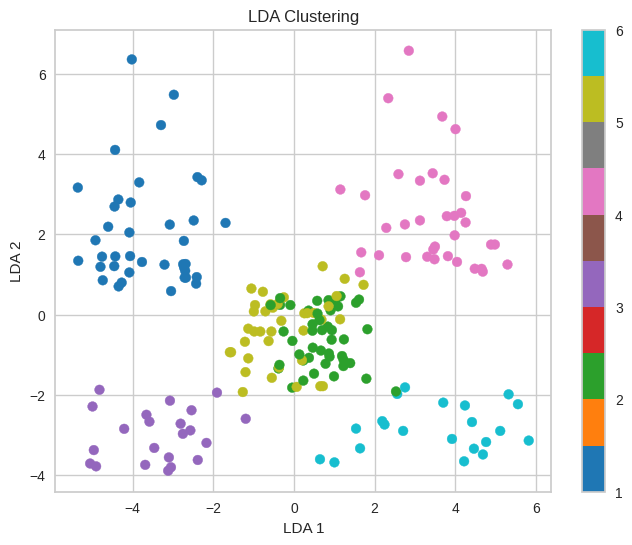

In [25]:
# LDA
lda = LinearDiscriminantAnalysis(n_components=2)
lda_result = lda.fit_transform(df[['Gender', 'Age', 'Income', 'Score']], df['Cluster'])
df['LDA1'] = lda_result[:,0]
df['LDA2'] = lda_result[:,1]

plt.figure(figsize=(8,6))
plt.scatter(df['LDA1'], df['LDA2'], c=df['Cluster']+1, cmap='tab10')
plt.xlabel('LDA 1')
plt.ylabel('LDA 2')
plt.title('LDA Clustering')
plt.colorbar()
plt.show()

            LDA1      LDA2
Gender -0.090348  0.243797
Age     0.031576  0.000335
Income -0.003333  0.082937
Score  -0.104734 -0.003319


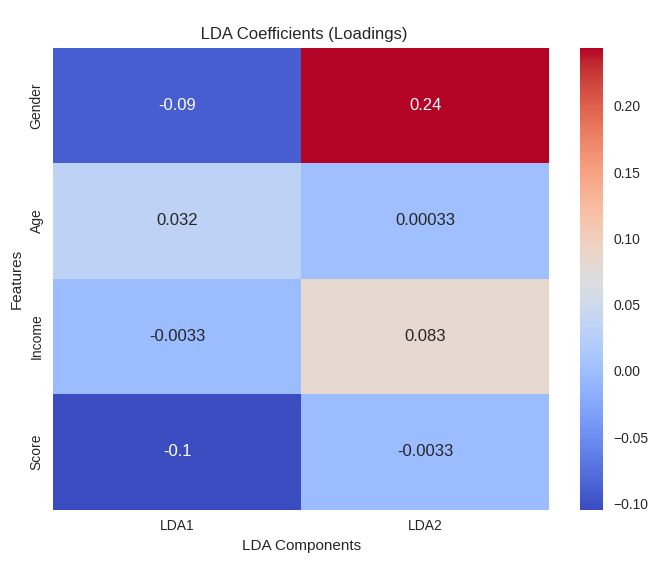

In [14]:
# feature importance
coefficients = pd.DataFrame(lda.scalings_[:, :2], index=['Gender', 'Age', 'Income', 'Score'], columns=['LDA1', 'LDA2'])
print(coefficients)

# Plot heatmap of LDA coefficients
plt.figure(figsize=(8, 6))
sns.heatmap(coefficients, annot=True, cmap='coolwarm')
plt.title('\n LDA Coefficients (Loadings)')
plt.xlabel('LDA Components')
plt.ylabel('Features')
plt.show()

Correlation absolute between features and cluster labels (LDA):
Score     0.648021
LDA1      0.595717
Income    0.370784
LDA2      0.346655
Age       0.163756
Gender    0.050626
Name: Cluster, dtype: float64


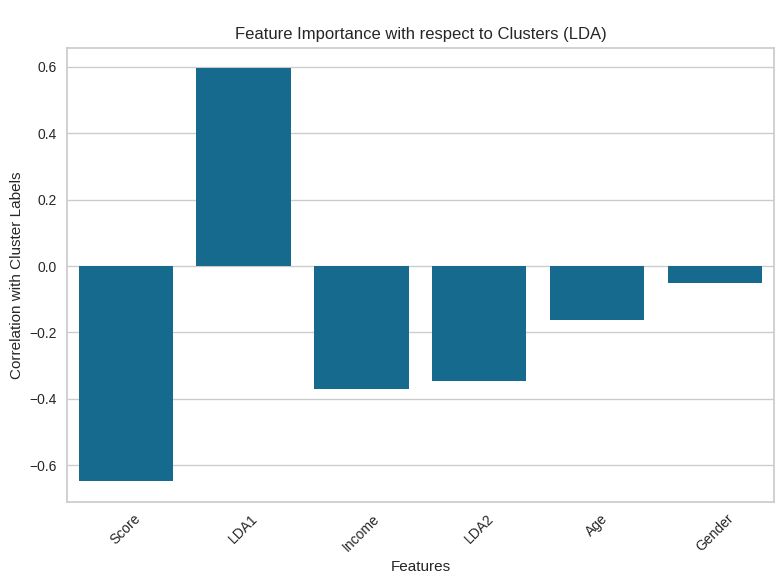

In [15]:
# Calculate correlation between features and cluster labels (LDA)
correlation_matrix_lda = df[['Gender', 'Age', 'Income', 'Score', 'LDA1', 'LDA2', 'Cluster']].corr()

if 'Cluster' in correlation_matrix_lda.index:
    correlation_matrix_lda = correlation_matrix_lda.drop('Cluster')

correlation_matrix_lda_sorted = correlation_matrix_lda['Cluster'].abs().sort_values(ascending=False)
print("Correlation absolute between features and cluster labels (LDA):")
print(correlation_matrix_lda_sorted)

# Bar plot of feature importance with respect to clusters (LDA)
plt.figure(figsize=(8, 6))
sns.barplot(x=correlation_matrix_lda_sorted.index, y=correlation_matrix_lda['Cluster'].loc[correlation_matrix_lda_sorted.index])
plt.title('\nFeature Importance with respect to Clusters (LDA)')
plt.xlabel('Features')
plt.ylabel('Correlation with Cluster Labels')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## **3- t-SNE**

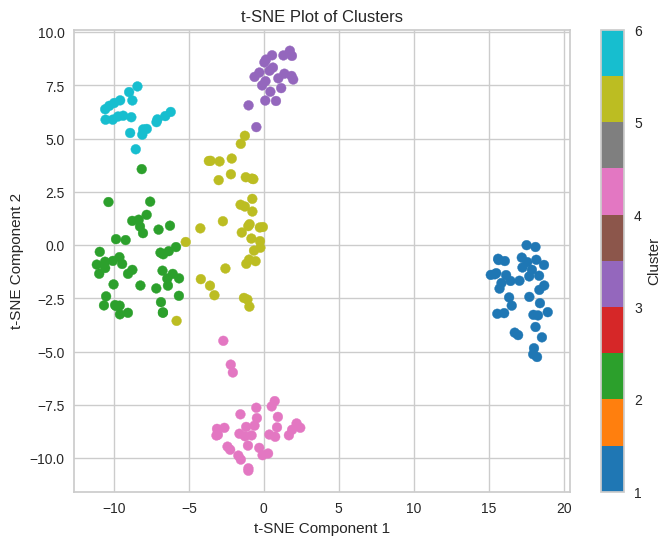

In [16]:
# t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(df[['Gender', 'Age', 'Income', 'Score']], df['Cluster'])
df['t-SNE 1'] = tsne_result[:,0]
df['t-SNE 2'] = tsne_result[:,1]

plt.figure(figsize=(8, 6))
plt.scatter(df['t-SNE 1'], df['t-SNE 2'], c=kmeanModel.labels_ + 1 , cmap='tab10')
plt.title('t-SNE Plot of Clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.colorbar(label='Cluster')
plt.show()

## **4- Pairplot of Features**

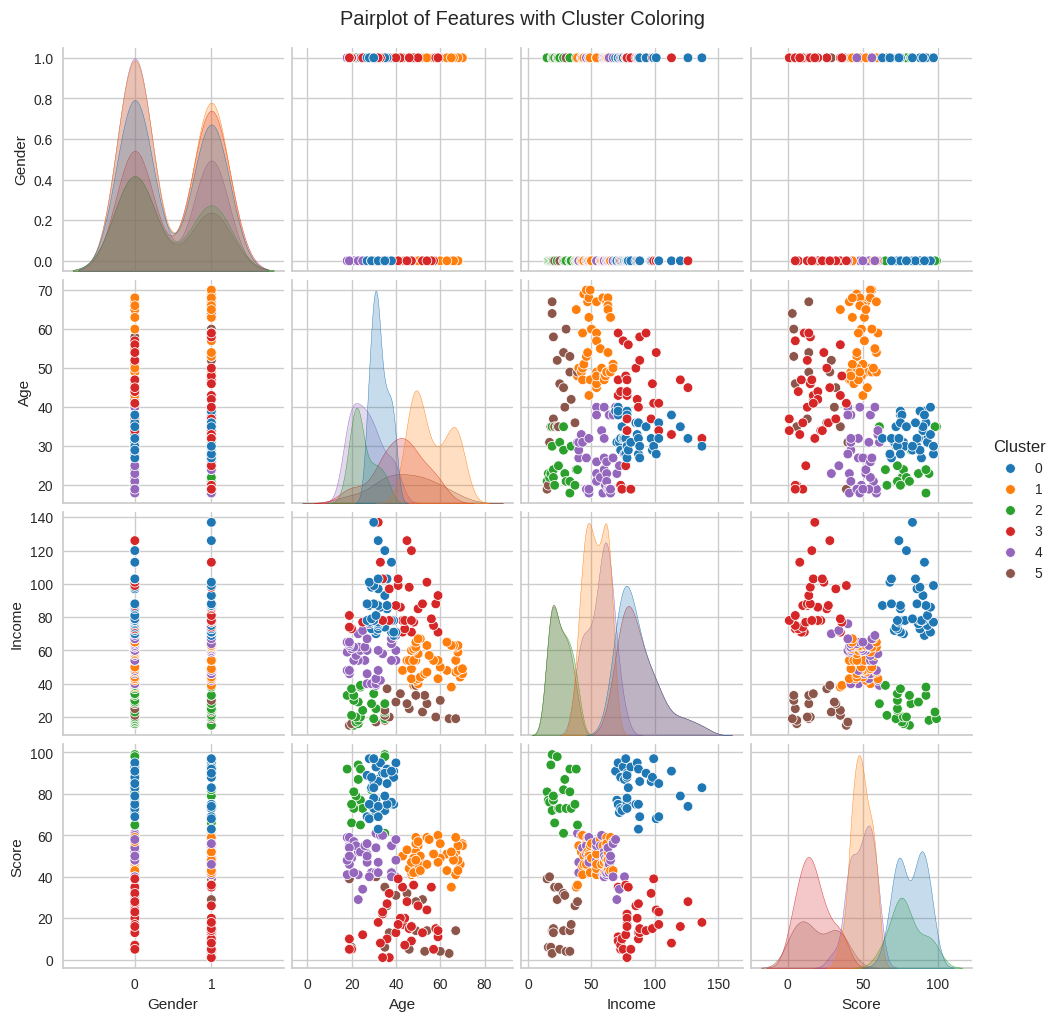

In [17]:
# pairplots
sns.pairplot(df[['Gender', 'Age', 'Income', 'Score', 'Cluster']], hue='Cluster', palette='tab10')
plt.suptitle('Pairplot of Features with Cluster Coloring', y=1.02)
plt.show()

In [19]:
from scipy.spatial.distance import cdist

labels = kmeanModel.fit_predict(df[['Gender', 'Age', 'Income', 'Score']])

silhouette_avg = silhouette_score(df[['Gender', 'Age', 'Income', 'Score']], labels)
davies_bouldin_avg = davies_bouldin_score(df[['Gender', 'Age', 'Income', 'Score']], labels)
calinski_harabasz_avg = calinski_harabasz_score(df[['Gender', 'Age', 'Income', 'Score']], labels)

print(f'Silhouette Score: {silhouette_avg}')
print(f'Davies-Bouldin Index: {davies_bouldin_avg}')
print(f'Calinski-Harabasz Index: {calinski_harabasz_avg}')

# Calculate Intra-cluster Distance
def calculate_intra_cluster_distance(X, labels, centroids):
    intra_distances = []
    for i in range(len(centroids)):
        cluster_points = X[labels == i]
        distances = cdist(cluster_points, [centroids[i]], 'euclidean')
        intra_distances.append(np.mean(distances))
    return np.mean(intra_distances)

# Calculate Inter-cluster Distance
def calculate_inter_cluster_distance(centroids):
    distances = cdist(centroids, centroids, 'euclidean')
    np.fill_diagonal(distances, np.nan)  # Ignore the diagonal
    return np.nanmean(distances)

centroids = kmeanModel.cluster_centers_
X = df[['Gender', 'Age', 'Income', 'Score']].values

intra_cluster_distance = calculate_intra_cluster_distance(X, labels, centroids)
inter_cluster_distance = calculate_inter_cluster_distance(centroids)

print(f'Intra-cluster Distance: {intra_cluster_distance}')
print(f'Inter-cluster Distance: {inter_cluster_distance}')

Silhouette Score: 0.45205475380756527
Davies-Bouldin Index: 0.7475215820921529
Calinski-Harabasz Index: 166.58349562213598
Intra-cluster Distance: 15.576869833507317
Inter-cluster Distance: 55.84175672816323




---



---



## **With preporocessing (It is NOT recommended.)**

In [20]:
file_path = '/content/drive/MyDrive/customers_dataset.csv'
data = pd.read_csv(file_path)

# encode categorical (Gender)
le = LabelEncoder()
data['Gender'] = le.fit_transform(data['Gender'])

# normalize data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(data[['Age', 'Income', 'Score']])
data[['Age', 'Income', 'Score']] = scaled_features
data.head()

,Gender,Age,Income,Score
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980


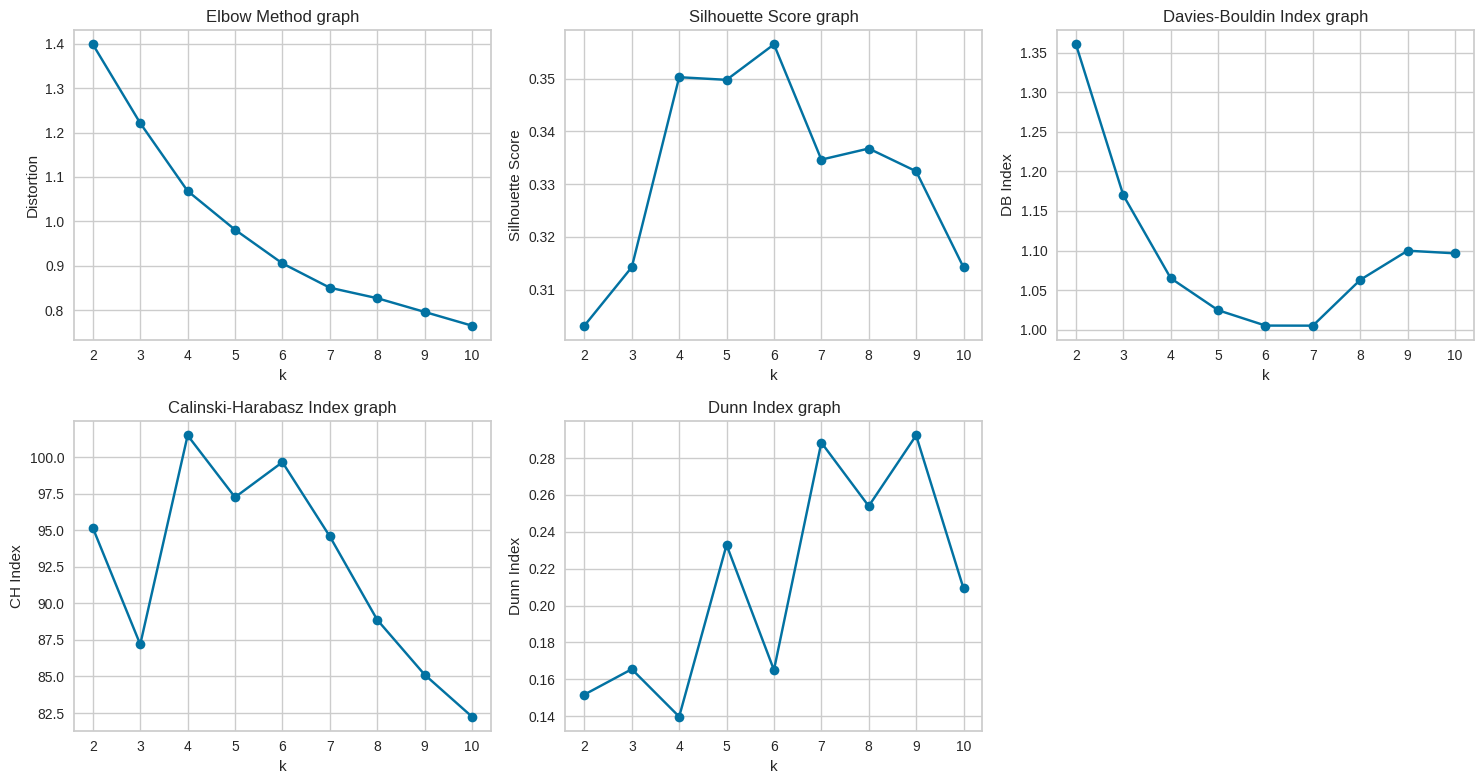

In [21]:
from scipy.spatial.distance import cdist

# K-means interia and Elbow
def compute_elbow(data, max_k):
    distortions = []
    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(data)
        distortions.append(sum(np.min(cdist(data, kmeans.cluster_centers_, 'euclidean'), axis=1)) / data.shape[0])
    return distortions

# Silhouette Score
def compute_silhouette(data, max_k):
    silhouette_scores = []
    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(data)
        score = silhouette_score(data, kmeans.labels_)
        silhouette_scores.append(score)
    return silhouette_scores

# Davies-Bouldin Index
def compute_davies_bouldin(data, max_k):
    db_scores = []
    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(data)
        score = davies_bouldin_score(data, kmeans.labels_)
        db_scores.append(score)
    return db_scores

# Calinski-Harabasz Index
def compute_calinski_harabasz(data, max_k):
    ch_scores = []
    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(data)
        score = calinski_harabasz_score(data, kmeans.labels_)
        ch_scores.append(score)
    return ch_scores

# Dunn Index
def compute_dunn(data, max_k):

    def dunn_index(X, labels):
        intra_distances = []
        inter_distances = []
        for k in np.unique(labels):
            cluster_points = X[labels == k]
            intra_distances.append(np.mean(pdist(cluster_points)))
            other_points = X[labels != k]
            if len(other_points) > 0:
                inter_distances.append(np.min(cdist(cluster_points, other_points)))
        dunn = min(inter_distances) / max(intra_distances)
        return dunn

    dunn_scores = []
    for k in range(2, max_k+1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(data)
        dunn_scores.append(dunn_index(data, kmeans.labels_))
    return dunn_scores

# for 2 to 10 clusters
max_k = 10
distortions = compute_elbow(data, max_k)
silhouette_scores = compute_silhouette(data, max_k)
db_scores = compute_davies_bouldin(data, max_k)
ch_scores = compute_calinski_harabasz(data, max_k)
dunn_scores = compute_dunn(data, max_k)

# plotting
plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 1)
plt.plot(range(2, max_k+1), distortions, marker='o')
plt.title('Elbow Method graph')
plt.xlabel('k')
plt.ylabel('Distortion')

plt.subplot(2, 3, 2)
plt.plot(range(2, max_k+1), silhouette_scores, marker='o')
plt.title('Silhouette Score graph')
plt.xlabel('k')
plt.ylabel('Silhouette Score')

plt.subplot(2, 3, 3)
plt.plot(range(2, max_k+1), db_scores, marker='o')
plt.title('Davies-Bouldin Index graph')
plt.xlabel('k')
plt.ylabel('DB Index')

plt.subplot(2, 3, 4)
plt.plot(range(2, max_k+1), ch_scores, marker='o')
plt.title('Calinski-Harabasz Index graph')
plt.xlabel('k')
plt.ylabel('CH Index')

plt.subplot(2, 3, 5)
plt.plot(range(2, max_k+1), dunn_scores, marker='o')
plt.title('Dunn Index graph')
plt.xlabel('k')
plt.ylabel('Dunn Index')
plt.tight_layout()
plt.show()

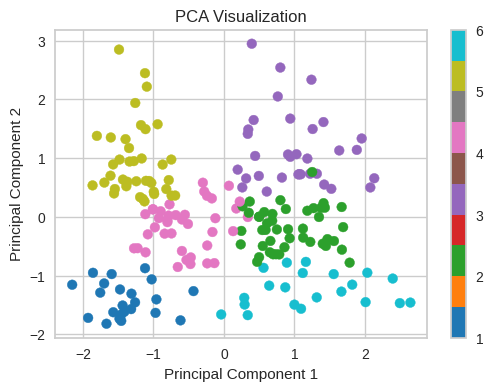

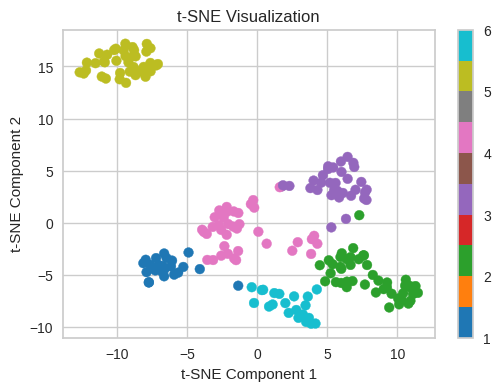

In [22]:
optimal_k = 6
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(data[['Age', 'Income', 'Score']])

# PCA
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data[['Age', 'Income', 'Score']])
plt.figure(figsize=(6, 4))
plt.scatter(data_pca[:, 0], data_pca[:, 1], c=data['Cluster']+1, cmap='tab10')
plt.title('PCA Visualization')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar()
plt.show()

# t-SNE
tsne = TSNE(n_components=2, random_state=42)
data_tsne = tsne.fit_transform(data[['Age', 'Income', 'Score']])
plt.figure(figsize=(6, 4))
plt.scatter(data_tsne[:, 0], data_tsne[:, 1], c=data['Cluster']+1, cmap='tab10')
plt.title('t-SNE Visualization')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.colorbar()
plt.show()

In [23]:
labels = kmeans.fit_predict(data[['Gender', 'Age', 'Income', 'Score']])

silhouette_avg = silhouette_score(data[['Gender', 'Age', 'Income', 'Score']], labels)
davies_bouldin_avg = davies_bouldin_score(data[['Gender', 'Age', 'Income', 'Score']], labels)
calinski_harabasz_avg = calinski_harabasz_score(data[['Gender', 'Age', 'Income', 'Score']], labels)

print(f'Silhouette Score: {silhouette_avg}')
print(f'Davies-Bouldin Index: {davies_bouldin_avg}')
print(f'Calinski-Harabasz Index: {calinski_harabasz_avg}')

# Calculate Intra-cluster Distance
def calculate_intra_cluster_distance(X, labels, centroids):
    intra_distances = []
    for i in range(len(centroids)):
        cluster_points = X[labels == i]
        distances = cdist(cluster_points, [centroids[i]], 'euclidean')
        intra_distances.append(np.mean(distances))
    return np.mean(intra_distances)

# Calculate Inter-cluster Distance
def calculate_inter_cluster_distance(centroids):
    distances = cdist(centroids, centroids, 'euclidean')
    np.fill_diagonal(distances, np.nan)
    return np.nanmean(distances)

centroids = kmeans.cluster_centers_
X = data[['Gender', 'Age', 'Income', 'Score']].values

intra_cluster_distance = calculate_intra_cluster_distance(X, labels, centroids)
inter_cluster_distance = calculate_inter_cluster_distance(centroids)

print(f'Intra-cluster Distance: {intra_cluster_distance}')
print(f'Inter-cluster Distance: {inter_cluster_distance}')

Silhouette Score: 0.356485834425401
Davies-Bouldin Index: 1.0050904211940697
Calinski-Harabasz Index: 99.65487851108833
Intra-cluster Distance: 0.9130994462619396
Inter-cluster Distance: 2.3942281448667924
